## Healthcare Analytics for Doctor Visits

##Import libraries

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, mannwhitneyu, chi2_contingency, spearmanr

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="darkgrid")

##Load Dataset

In [57]:
file_path = "/content/1776250375-P2-Healthcare Analytics for Doctor Visits (1).csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (5190, 13)


,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.190,0.550,1,4,1,yes,no,no,no,no
1,2,1,female,0.190,0.450,1,2,1,yes,no,no,no,no
2,3,1,male,0.190,0.900,3,0,0,no,no,no,no,no
3,4,1,male,0.190,0.150,1,0,0,no,no,no,no,no
4,5,1,male,0.190,0.450,2,5,1,no,no,no,yes,no


##Understanding Data

In [83]:
print("Dataset shape:", df.shape)

print("Columns:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all").T)

Dataset shape: (5190, 13)
Columns:
['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced', 'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic']

Data types:


,dtype
Unnamed: 0,int64
visits,int64
gender,object
age,float64
income,float64
illness,int64
reduced,int64
health,int64
private,object
freepoor,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,"5,190.000",NaN,NaN,NaN,"2,595.500","1,498.368",1.000,"1,298.250","2,595.500","3,892.750","5,190.000"
visits,"5,190.000",NaN,NaN,NaN,0.302,0.798,0.000,0.000,0.000,0.000,9.000
gender,5190,2,female,2702,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"5,190.000",NaN,NaN,NaN,0.406,0.205,0.190,0.220,0.320,0.620,0.720
income,"5,190.000",NaN,NaN,NaN,0.583,0.369,0.000,0.250,0.550,0.900,1.500
illness,"5,190.000",NaN,NaN,NaN,1.432,1.384,0.000,0.000,1.000,2.000,5.000
reduced,"5,190.000",NaN,NaN,NaN,0.862,2.888,0.000,0.000,0.000,0.000,14.000
health,"5,190.000",NaN,NaN,NaN,1.218,2.124,0.000,0.000,0.000,2.000,12.000
private,5190,2,no,2892,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freepoor,5190,2,no,4968,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##Data Quality Check

In [59]:
print("Missing values:")
display(df.isna().sum().to_frame("missing_values"))

print("Duplicate rows:", df.duplicated().sum())

print("\nUnique values:")
for col in df.columns:
    print(f"{col}: {df[col].nunique()}")

Missing values:


,missing_values
Unnamed: 0,0
visits,0
gender,0
age,0
income,0
illness,0
reduced,0
health,0
private,0
freepoor,0


Duplicate rows: 0

Unique values:
Unnamed: 0: 5190
visits: 10
gender: 2
age: 12
income: 14
illness: 6
reduced: 15
health: 13
private: 2
freepoor: 2
freerepat: 2
nchronic: 2
lchronic: 2


##Cleaning Data

In [60]:
df_clean = df.copy()

# Remove exported index column
if "Unnamed: 0" in df_clean.columns:
    df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Standardize categorical columns
categorical_cols = [
    "gender", "private", "freepoor", "freerepat",
    "nchronic", "lchronic"
]

for col in categorical_cols:
    df_clean[col] = df_clean[col].astype(str).str.strip().str.lower()

# Numeric columns
numeric_cols = [
    "visits", "age", "income", "illness",
    "reduced", "health"
]

for col in numeric_cols:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Final validation
print("Shape after cleaning:", df_clean.shape)
print("Missing values after cleaning:", df_clean.isna().sum().sum())
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

display(df_clean.head())

Shape after cleaning: (5190, 12)
Missing values after cleaning: 0
Duplicate rows after cleaning: 1320


,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,female,0.190,0.550,1,4,1,yes,no,no,no,no
1,1,female,0.190,0.450,1,2,1,yes,no,no,no,no
2,1,male,0.190,0.900,3,0,0,no,no,no,no,no
3,1,male,0.190,0.150,1,0,0,no,no,no,no,no
4,1,male,0.190,0.450,2,5,1,no,no,no,yes,no


##Feature Engg

In [61]:
# Dr visit status
df_clean["visited_doctor"] = np.where(df_clean["visits"] > 0, "Yes", "No")

# Age bands based on the supplied encoded age values
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 0.30, 0.45, 0.60, 0.73],
    labels=["Young", "Adult", "Middle-aged", "Older"],
    include_lowest=True
)

# Chronic condition count
df_clean["chronic_condition_count"] = (
    (df_clean["nchronic"] == "yes").astype(int) +
    (df_clean["lchronic"] == "yes").astype(int)
)

display(df_clean.head())

,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic,visited_doctor,age_group,chronic_condition_count
0,1,female,0.190,0.550,1,4,1,yes,no,no,no,no,Yes,Young,0
1,1,female,0.190,0.450,1,2,1,yes,no,no,no,no,Yes,Young,0
2,1,male,0.190,0.900,3,0,0,no,no,no,no,no,Yes,Young,0
3,1,male,0.190,0.150,1,0,0,no,no,no,no,no,Yes,Young,0
4,1,male,0.190,0.450,2,5,1,no,no,no,yes,no,Yes,Young,1


In [62]:
# KPIs
total_people = len(df_clean)
total_visits = df_clean["visits"].sum()
people_with_visit = (df_clean["visits"] > 0).sum()
visit_rate = people_with_visit / total_people * 100
avg_visits = df_clean["visits"].mean()

kpis = pd.DataFrame({
    "Metric": [
        "Total records",
        "Total doctor visits",
        "People with at least one visit",
        "Doctor visit rate",
        "Average visits per person",
        "Maximum visits by one person"
    ],
    "Value": [
        total_people,
        total_visits,
        people_with_visit,
        f"{visit_rate:.2f}%",
        round(avg_visits, 3),
        df_clean["visits"].max()
    ]
})

display(kpis)

,Metric,Value
0,Total records,5190
1,Total doctor visits,1566
2,People with at least one visit,1049
3,Doctor visit rate,20.21%
4,Average visits per person,0.302
5,Maximum visits by one person,9


## Univariate Analysis

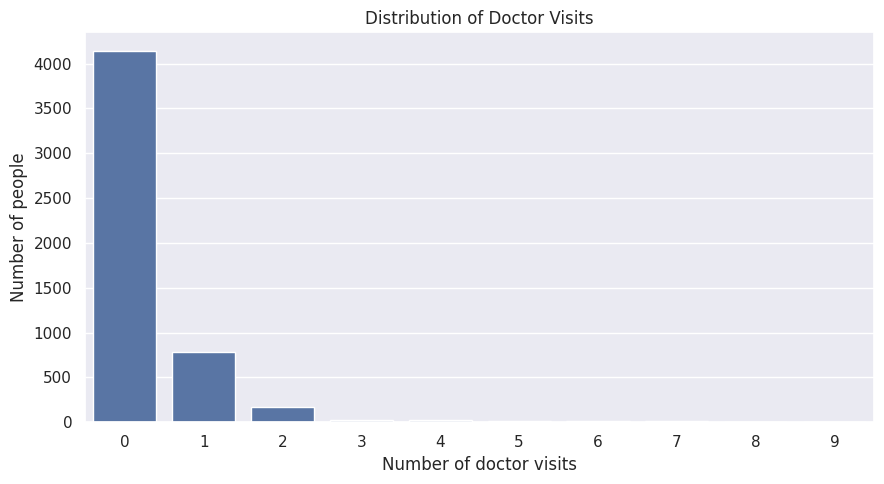

visits
0    4141
1     782
2     174
3      30
4      24
5       9
6      12
7      12
8       5
9       1
Name: count, dtype: int64


In [63]:
# Distribution of doctor visits
plt.figure(figsize=(9, 5))
sns.countplot(data=df_clean, x="visits")
plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of doctor visits")
plt.ylabel("Number of people")

plt.tight_layout()
plt.savefig('Distribution of Dr visit', dpi=150)
plt.show()

print(df_clean["visits"].value_counts().sort_index())

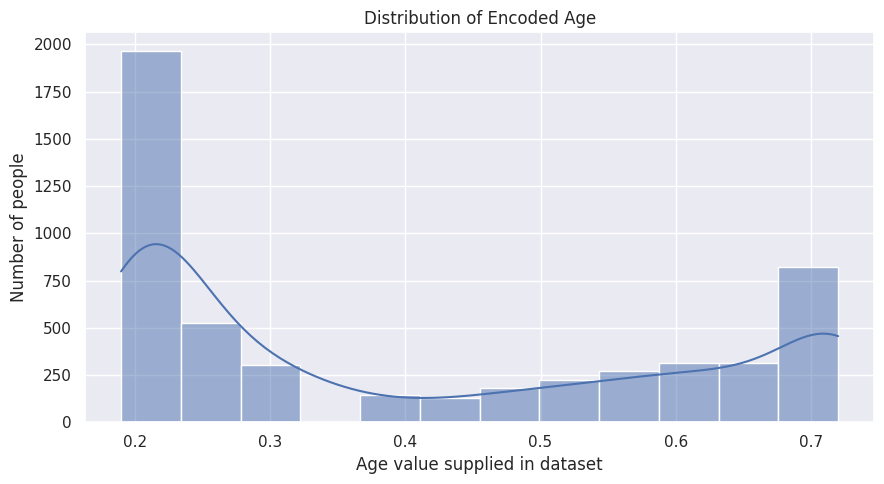

In [64]:
# Distribution of age
plt.figure(figsize=(9, 5))
sns.histplot(data=df_clean, x="age", bins=12, kde=True)
plt.title("Distribution of Encoded Age")
plt.xlabel("Age value supplied in dataset")
plt.ylabel("Number of people")

plt.tight_layout()
plt.savefig('Distribution of Age', dpi=150)
plt.show()

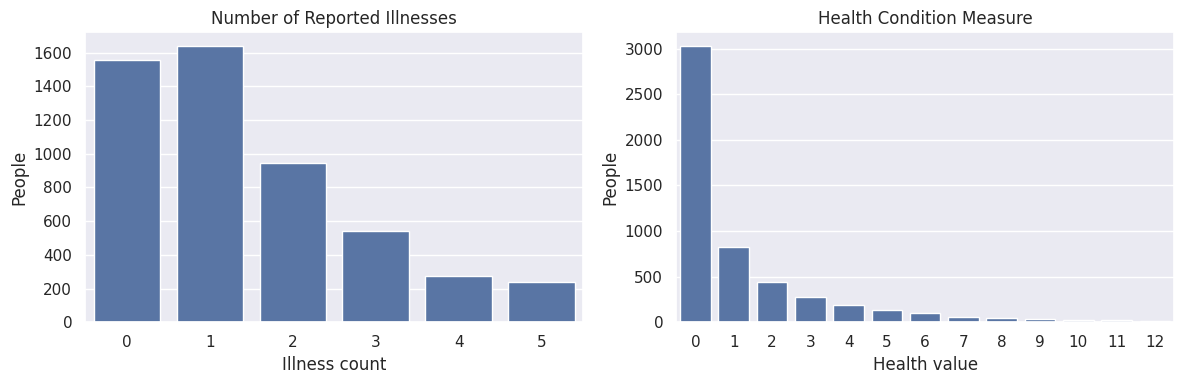

In [65]:
# Distribution of illness and health indicators
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df_clean, x="illness", ax=axes[0])
axes[0].set_title("Number of Reported Illnesses")
axes[0].set_xlabel("Illness count")
axes[0].set_ylabel("People")

sns.countplot(data=df_clean, x="health", ax=axes[1])
axes[1].set_title("Health Condition Measure")
axes[1].set_xlabel("Health value")
axes[1].set_ylabel("People")

plt.tight_layout()
plt.savefig('Distribution of Illness and Health', dpi=150)
plt.show()

## Categorical Analysis

In [67]:
def segment_summary(df, col):
    df["visited_doctor"] = df["visits"] > 0

    return (
        df.groupby(col).agg(
              people=("visits", "size"),
              people_with_visit=("visited_doctor", "sum"),
              total_visits=("visits", "sum"),
              average_visits=("visits", "mean")
          )
          .assign(visit_rate_pct=lambda x: x.people_with_visit / x.people * 100)
          .sort_values("average_visits", ascending=False)
          .reset_index()
    )

for col in ["gender", "private", "freepoor", "freerepat", "nchronic", "lchronic"]:
    print(f"\n--- {col} ---")
    display(segment_summary(df_clean, col))


--- gender ---


,gender,people,people_with_visit,total_visits,average_visits,visit_rate_pct
0,female,2702,660,978,0.362,24.426
1,male,2488,389,588,0.236,15.635



--- private ---


,private,people,people_with_visit,total_visits,average_visits,visit_rate_pct
0,no,2892,589,889,0.307,20.367
1,yes,2298,460,677,0.295,20.017



--- freepoor ---


...

,freerepat,people,people_with_visit,total_visits,average_visits,visit_rate_pct
0,yes,1091,345,509,0.467,31.622
1,no,4099,704,1057,0.258,17.175



--- nchronic ---


,nchronic,people,people_with_visit,total_visits,average_visits,visit_rate_pct
0,yes,2092,495,723,0.346,23.662
1,no,3098,554,843,0.272,17.883



--- lchronic ---


,lchronic,people,people_with_visit,total_visits,average_visits,visit_rate_pct
0,yes,605,212,365,0.603,35.041
1,no,4585,837,1201,0.262,18.255


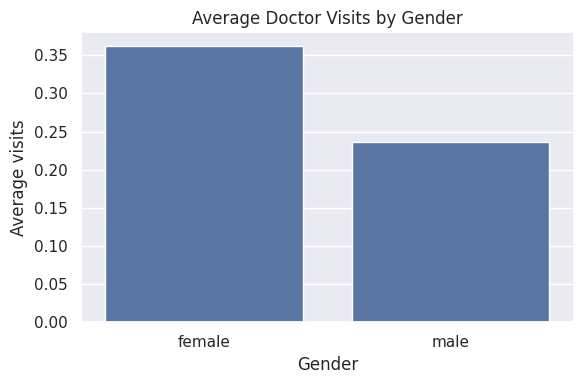

In [88]:
# Average visits by gender
gender_summary = df_clean.groupby("gender")["visits"].mean().sort_values(ascending=False)

plt.figure(figsize=(6, 4))
sns.barplot(x=gender_summary.index, y=gender_summary.values)
plt.title("Average Doctor Visits by Gender")
plt.xlabel("Gender")
plt.ylabel("Average visits")

plt.tight_layout()
plt.savefig('Average Visits by Gender', dpi=150)
plt.show()

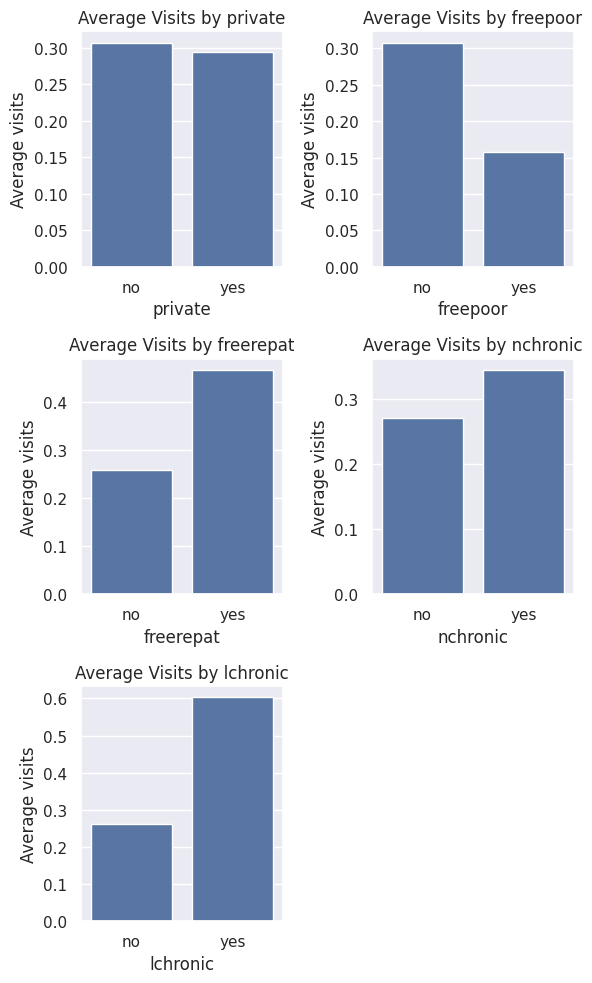

In [91]:
# Average visits by insurance/access variables
access_cols = ["private", "freepoor", "freerepat", "nchronic", "lchronic"]

fig, axes = plt.subplots(3, 2, figsize=(6, 10))
axes = axes.flatten()

for ax, col in zip(axes, access_cols):
    summary = df_clean.groupby(col)["visits"].mean()
    sns.barplot(x=summary.index, y=summary.values, ax=ax)
    ax.set_title(f"Average Visits by {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Average visits")

axes[-1].axis("off")
plt.tight_layout()
plt.savefig('Average Visits by Access', dpi=150)
plt.show()

,age_group,count,mean,sum
0,Young,2488,0.217,539
1,Adult,573,0.260,149
2,Middle-aged,676,0.370,250
3,Older,1453,0.432,628


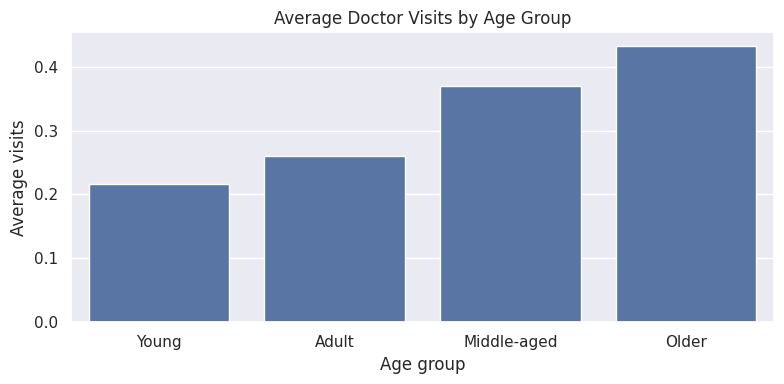

In [92]:
# Age group comparison
age_summary = df_clean.groupby("age_group", observed=True)["visits"].agg(
    ["count", "mean", "sum"]
).reset_index()

display(age_summary)

plt.figure(figsize=(8, 4))
sns.barplot(data=age_summary, x="age_group", y="mean")
plt.title("Average Doctor Visits by Age Group")
plt.xlabel("Age group")
plt.ylabel("Average visits")

plt.tight_layout()
plt.savefig('Average Visits by Age', dpi=150)
plt.show()

##Health and Utilization Relationships

In [71]:
# Spearman correlation with doctor visits
corr_vars = [
    "visits", "age", "income", "illness",
    "reduced", "health", "chronic_condition_count"
]

spearman_results = []

for i in corr_vars:
    if i != "visits":
        r, p = spearmanr(df_clean["visits"], df_clean[i])

        spearman_results.append({
            "Variable": i,
            "Spearman_correlation": r,
            "p_value": p
        })

# Convert results into a DataFrame
corr_df = pd.DataFrame(spearman_results).sort_values(
    "Spearman_correlation", key=lambda s: s.abs(), ascending=False
)

display(corr_df)

,Variable,Spearman_correlation,p_value
3,reduced,0.336,0.000
2,illness,0.263,0.000
4,health,0.178,0.000
5,chronic_condition_count,0.158,0.000
0,age,0.148,0.000
1,income,-0.093,0.000


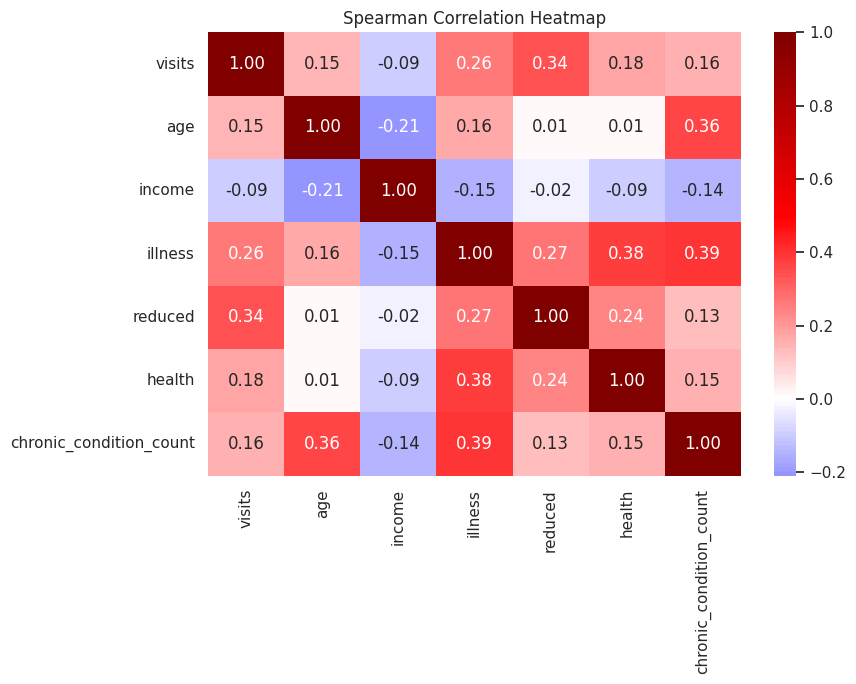

In [72]:
# Correlation heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    df_clean[corr_vars].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="seismic",
    center=0
)
plt.title("Spearman Correlation Heatmap")
plt.tight_layout()
plt.savefig('Correlation Heatmap', dpi=150)
plt.show()

,illness,count,mean,sum
0,0,1554,0.079,122
1,1,1638,0.295,484
2,2,946,0.404,382
3,3,542,0.421,228
4,4,274,0.577,158
5,5,236,0.814,192


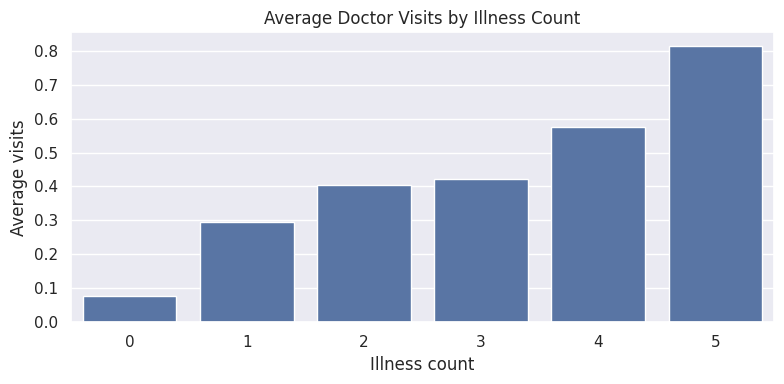

In [93]:
# Illness vs doctor visits
illness_summary = df_clean.groupby("illness")["visits"].agg(
    ["count", "mean", "sum"]
).reset_index()

display(illness_summary)

plt.figure(figsize=(8, 4))
sns.barplot(data=illness_summary, x="illness", y="mean")
plt.title("Average Doctor Visits by Illness Count")
plt.xlabel("Illness count")
plt.ylabel("Average visits")
plt.tight_layout()
plt.savefig('Illness vs Doctor Visits', dpi=150)
plt.show()

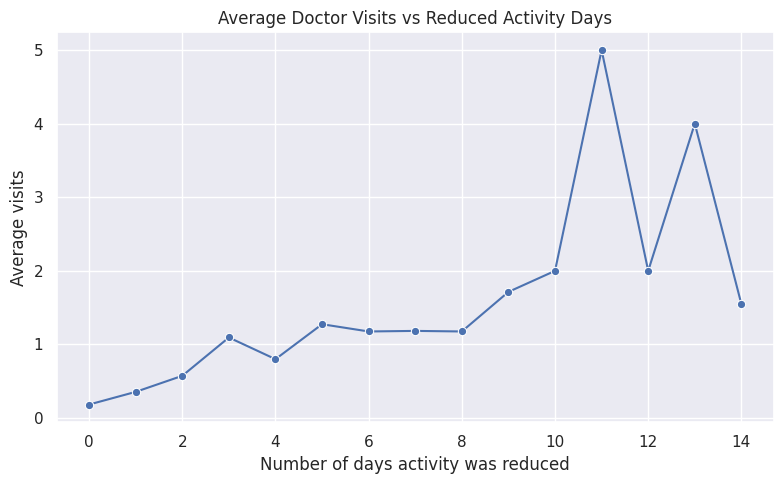

In [94]:
# Activity limitation vs doctor visits
reduced_summary = df_clean.groupby("reduced")["visits"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(data=reduced_summary, x="reduced", y="visits", marker="o")
plt.title("Average Doctor Visits vs Reduced Activity Days")
plt.xlabel("Number of days activity was reduced")
plt.ylabel("Average visits")

plt.tight_layout()
plt.savefig('Activity Limitation vs Doctor Visits', dpi=150)
plt.show()

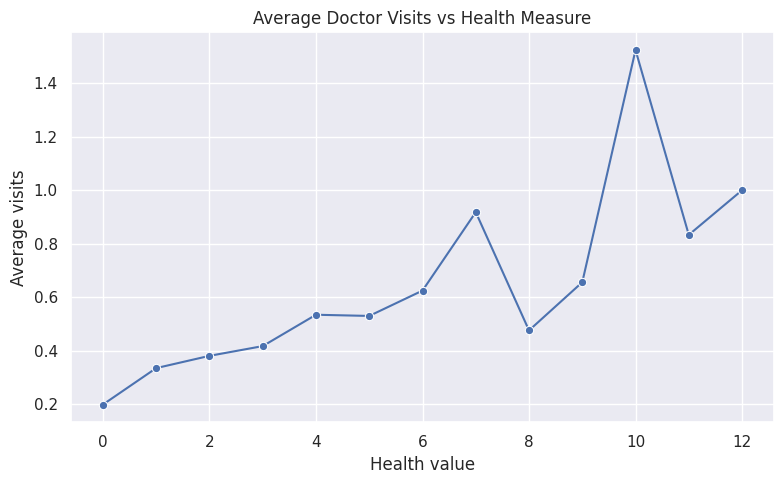

In [96]:
# Health measure vs doctor visits
health_summary = df_clean.groupby("health")["visits"].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.lineplot(data=health_summary, x="health", y="visits", marker="o")
plt.title("Average Doctor Visits vs Health Measure")
plt.xlabel("Health value")
plt.ylabel("Average visits")
plt.tight_layout()
plt.savefig('Health Measure vs Doctor Visits', dpi=150)
plt.show()

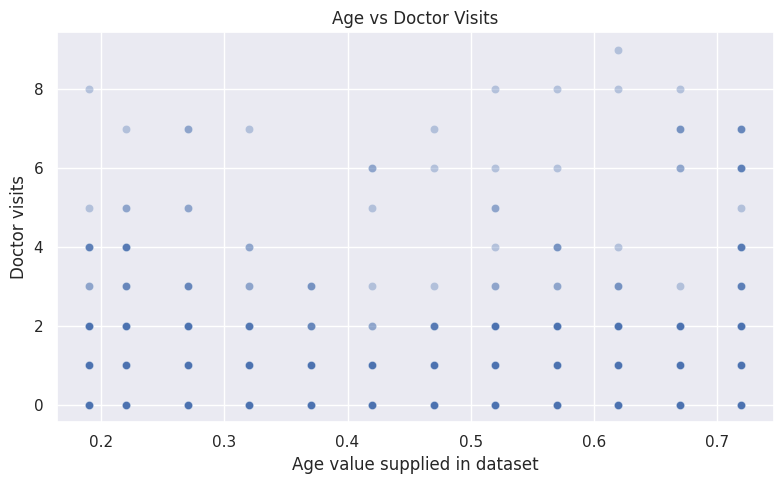

In [97]:
# Scatter: age vs visits
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_clean,
    x="age",
    y="visits",
    alpha=0.35
)
plt.title("Age vs Doctor Visits")
plt.xlabel("Age value supplied in dataset")
plt.ylabel("Doctor visits")

plt.tight_layout()
plt.savefig('Age vs Doctor Visits', dpi=150)
plt.show()

## Doctor-Visit Rate Analysis

In [77]:
# Visit rate by major categorical variables
rate_tables = []

for i in ["gender", "private", "freepoor", "freerepat", "nchronic", "lchronic"]:
    temp = df_clean.groupby(col)["visited_doctor"].apply(
        lambda x: (x == "Yes").mean() * 100
    ).reset_index(name="visit_rate_pct")

    temp["variable"] = col
    temp = temp.rename(columns={col: "group"})
    rate_tables.append(temp)

visit_rates = pd.concat(rate_tables, ignore_index=True)
display(visit_rates)

,group,visit_rate_pct,variable
0,no,0.000,lchronic
1,yes,0.000,lchronic
2,no,0.000,lchronic
3,yes,0.000,lchronic
4,no,0.000,lchronic
5,yes,0.000,lchronic
6,no,0.000,lchronic
7,yes,0.000,lchronic
8,no,0.000,lchronic
9,yes,0.000,lchronic


##Statistical Testing

In [78]:
# Mann Whitney U Test : visit distribution across selected binary variables

binary_cols = ["gender", "private", "freepoor", "freerepat", "nchronic", "lchronic"]

mw_results = []

for i in binary_cols:
    groups = [g["visits"].values for _, g in df_clean.groupby(i)]
    labels = list(df_clean.groupby(i).groups.keys())

    stat, p = mannwhitneyu(groups[0], groups[1], alternative="two-sided")
    mw_results.append({
        "Variable": i,
        "U_statistic": stat,
        "p_value": p
    })

mw_df = pd.DataFrame(mw_results)
display(mw_df)


,Variable,U_statistic,p_value
0,gender,"3,655,194.500",0.000
1,private,"3,334,282.500",0.762
2,freepoor,"615,824.500",0.000
3,freerepat,"1,914,797.000",0.000
4,nchronic,"3,055,466.000",0.000
5,lchronic,"1,144,248.000",0.000


In [79]:
# Chi-Square Test : doctor-visit status vs categorical variables

chi_results = []

for col in binary_cols:
    table = pd.crosstab(df_clean[col], df_clean["visited_doctor"])
    chi2, p, dof, expected = chi2_contingency(table)

    chi_results.append({
        "Variable": col,
        "Chi2": chi2,
        "p_value": p,
        "degrees_of_freedom": dof
    })

chi_df = pd.DataFrame(chi_results).sort_values("p_value")
display(chi_df)


,Variable,Chi2,p_value,degrees_of_freedom
3,freerepat,110.631,0.000,1
5,lchronic,92.348,0.000,1
0,gender,61.533,0.000,1
4,nchronic,25.504,0.000,1
2,freepoor,17.331,0.000,1
1,private,0.076,0.782,1


## High-Utilization Analysis

In [80]:
# High-utilization patients
high_util = df_clean[df_clean["visits"] >= 3].copy()

print("People with 3+ visits:", len(high_util))
print("Share of all people:", round(len(high_util) / len(df_clean) * 100, 2), "%")
print("Visits generated by 3+ visit group:", high_util["visits"].sum())
print("Share of all visits:", round(high_util["visits"].sum() / df_clean["visits"].sum() * 100, 2), "%")

display(
    high_util.groupby("age_group", observed=True)["visits"]
    .agg(["count", "mean", "sum"])
    .reset_index()
)


People with 3+ visits: 93
Share of all people: 1.79 %
Visits generated by 3+ visit group: 436
Share of all visits: 27.84 %


,age_group,count,mean,sum
0,Young,30,4.267,128
1,Adult,12,4.167,50
2,Middle-aged,17,4.824,82
3,Older,34,5.176,176


In [81]:
# Compare zero-visit and visited groups on selected measures
utilization_comparison = df_clean.groupby("visited_doctor")[
    ["age", "income", "illness", "reduced", "health", "chronic_condition_count"]
].mean().T

display(utilization_comparison)


visited_doctor,False,True
age,0.390,0.470
income,0.598,0.525
illness,1.256,2.126
reduced,0.426,2.581
health,1.022,1.990
chronic_condition_count,0.481,0.674


In [82]:
# Export cleaned dataset

output_file = "healthcare_doctor_visits_cleaned.csv"
df_clean.to_csv(output_file, index=False)

print(f"Cleaned dataset saved as: {output_file}")
print("Final shape:", df_clean.shape)


Cleaned dataset saved as: healthcare_doctor_visits_cleaned.csv
Final shape: (5190, 15)
